### NYC DOT Marketing Mix Modeling -- Data Analysis

The exploratory analysis identified several characteristics relevant to modeling, including sparse advertising activity, correlated media channels, seasonality, and a gradual decline in crash frequency.

Based on the observed correlations, I expected TV and Print to exhibit stronger relationships with crash outcomes. However, these initial findings do not establish advertising effectiveness, and further modeling is necessary to evaluate channel contributions while accounting for other factors.

#### Import libraries

In [1]:
# Core analysis libraries
import pandas as pd
import numpy as np
from datetime import date, timedelta
from pathlib import Path

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
sns.set() # Use Seaborn styling for all plots

# Show all columns
pd.set_option('display.max_columns', None)

#### File paths

In [2]:
# File paths
PROJECT_ROOT = Path.cwd().resolve().parent
SRC_DIR = PROJECT_ROOT / "src"
CLEAN_DATA_DIR = PROJECT_ROOT / "data/clean_data"
RAW_DATA_DIR = PROJECT_ROOT / "data/raw_data"
MODELS_DIR = PROJECT_ROOT / "models"
DEPLOYMENT_DIR = PROJECT_ROOT / "deployment"

#### Import data

In [3]:
data = pd.read_parquet(CLEAN_DATA_DIR / "01_dot_mmm_preprocessing.parquet")
data.head()

,week_start,spend_safety_tv,spend_safety_radio,spend_safety_print,spend_safety_digital_social,spend_safety_ooh_other,crashes,injured,killed,t,is_holiday_week,post_congestion
0,2022-07-04,0.00,0.00,0.00,0.00,0.00,1919,1053,12,0,1,0
1,2022-07-11,21920.83,3129.63,3209.92,0.00,18135.30,1994,1191,9,1,0,0
2,2022-07-18,25574.30,3651.24,3744.90,0.00,21157.85,2086,1183,10,2,0,0
3,2022-07-25,25574.30,3651.24,53479.90,5730.00,35958.85,2044,1020,5,3,0,0
4,2022-08-01,25574.30,3651.24,60952.90,2996.45,36106.01,2113,1127,5,4,0,0


In [4]:
# Number of rows and columns
data.shape

(156, 12)

In [5]:
# Descriptive statistics
data.describe().round(2)

,week_start,spend_safety_tv,spend_safety_radio,spend_safety_print,spend_safety_digital_social,spend_safety_ooh_other,crashes,injured,killed,t,is_holiday_week,post_congestion
count,156,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00,156.00
mean,2023-12-28 12:00:00,17659.90,16762.86,5937.36,7721.14,26220.88,1798.78,1015.56,5.21,77.50,0.22,0.16
min,2022-07-04 00:00:00,0.00,0.00,0.00,0.00,0.00,1374.00,723.00,0.00,0.00,0.00,0.00
25%,2023-04-01 06:00:00,0.00,0.00,0.00,0.00,0.00,1699.00,943.50,3.00,38.75,0.00,0.00
50%,2023-12-28 12:00:00,0.00,0.00,0.00,0.00,0.00,1803.50,1021.00,5.00,77.50,0.00,0.00
75%,2024-09-24 18:00:00,25574.30,10614.04,4250.00,5874.39,22812.50,1915.50,1109.00,7.00,116.25,0.00,0.00
max,2025-06-23 00:00:00,200239.52,109943.77,60952.90,54590.43,201845.51,2188.00,1267.00,12.00,155.00,1.00,1.00
std,NaN,33397.25,33103.62,11231.92,14468.26,50149.92,167.85,111.62,2.62,45.18,0.41,0.37


#### Data types and nulls

In [6]:
# Data types and nulls
data_types_null_counts = pd.DataFrame()
data_types_null_counts["Data Type"] = data.dtypes
data_types_null_counts["Count of Nulls"] = data.isna().sum()
data_types_null_counts

,Data Type,Count of Nulls
week_start,datetime64[ns],0
spend_safety_tv,float64,0
spend_safety_radio,float64,0
spend_safety_print,float64,0
spend_safety_digital_social,float64,0
spend_safety_ooh_other,float64,0
crashes,int64,0
injured,int64,0
killed,int64,0
t,int64,0


#### Advertising Spending Activity

Percentage of weeks with zero advertising spend to assess spending sparsity across channels and identify potential limitations for modeling.

In [7]:
float_cols_list = []

float_cols = data.select_dtypes(include=["float"])

for f in float_cols:
    total_rows = len(data)
    zeroes_count = data[data[f] == 0.0].shape[0]
    float_cols_list.append({
        "feature_name": f,
        "num_zeroes_rows": zeroes_count,
        "pct_zeroes_rows": round((zeroes_count / total_rows), 3)
    })

float_cols_count_df = pd.DataFrame(float_cols_list).sort_values(by="num_zeroes_rows", ascending=False)
float_cols_count_df

,feature_name,num_zeroes_rows,pct_zeroes_rows
3,spend_safety_digital_social,101,0.647
4,spend_safety_ooh_other,92,0.590
1,spend_safety_radio,89,0.571
0,spend_safety_tv,86,0.551
2,spend_safety_print,84,0.538


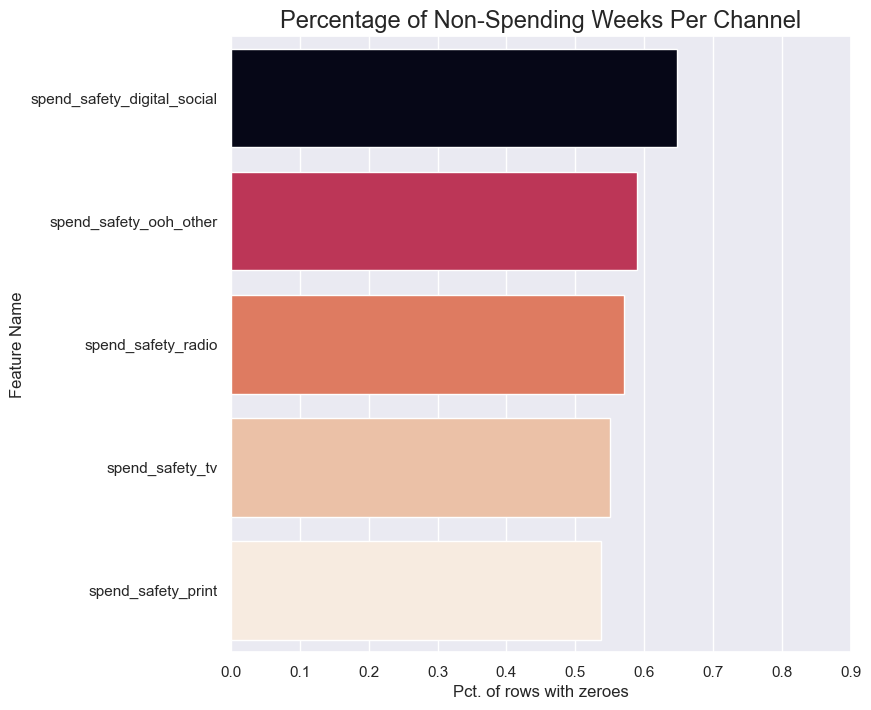

In [8]:
# Plot data
plt.figure(figsize=(8, 8))

sns.barplot(
    data=float_cols_count_df,
    y=float_cols_count_df["feature_name"],
    x="pct_zeroes_rows",
    hue="pct_zeroes_rows",
    palette="rocket_r",
    legend=False
)

plt.ylabel("Feature Name")
plt.xlabel("Pct. of rows with zeroes")
plt.xticks(np.arange(0, 1, 0.1))
plt.title("Percentage of Non-Spending Weeks Per Channel", fontsize=17)

plt.show()

#### Weekly Crash, Injury, and Fatality Trends

Weekly crash, injury, and fatality trends to identify seasonality and longer-term patterns. Crashes and injuries showed a gradual downward trend, with lower counts during winter months, suggesting the need to account for both trend and seasonality in the model.

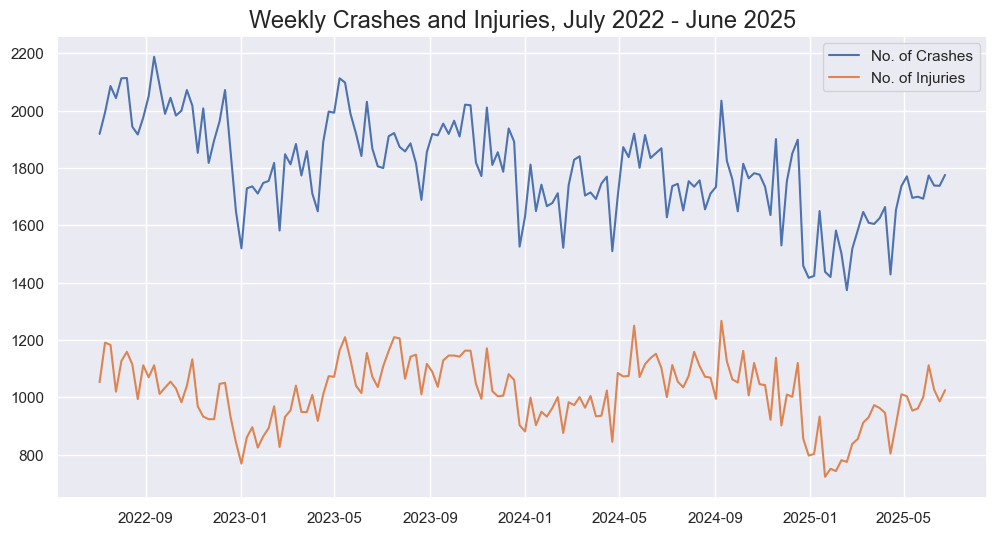

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(data["week_start"], data["crashes"], label="No. of Crashes")
plt.plot(data["week_start"], data["injured"], label="No. of Injuries")
plt.legend()
plt.title("Weekly Crashes and Injuries, July 2022 - June 2025", fontsize=17)
plt.show()

#### Crash and Injury Correlation

Correlation between weekly crashes and injuries to confirm their expected positive relationship.

In [10]:
data["injured"].corr(data["crashes"]).round(3)

np.float64(0.75)

#### Weekly Fatality Distribution

Weekly fatalities were generally concentrated between 4 and 8 deaths, with relatively few observations at the extremes of the distribution.

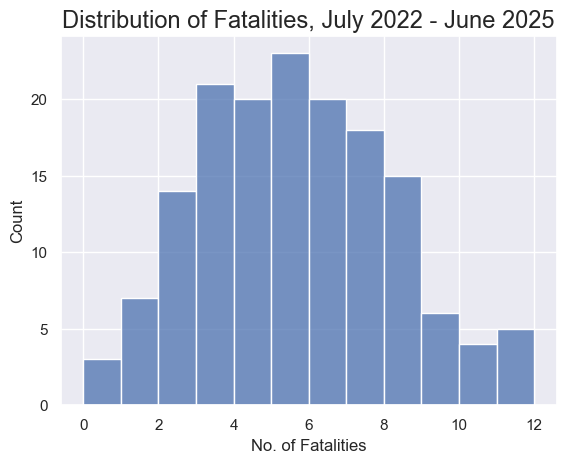

In [11]:
# Distributions
sns.histplot(
    data=data["killed"],
    bins=12
)
plt.xlabel("No. of Fatalities")
plt.title("Distribution of Fatalities, July 2022 - June 2025", fontsize=17)

plt.show()

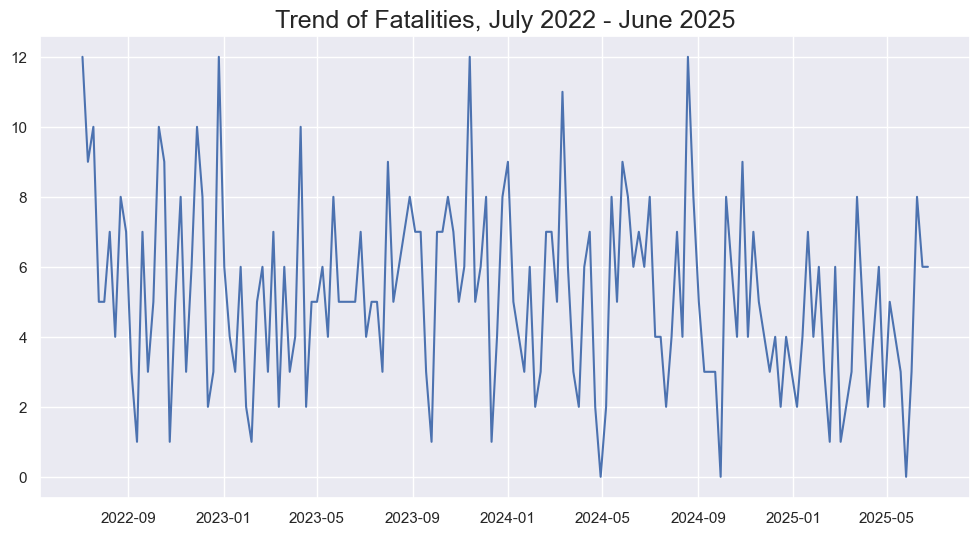

In [12]:
# Trend of fatalities
plt.figure(figsize=(12, 6))
plt.plot(data["week_start"], data["killed"])
plt.title("Trend of Fatalities, July 2022 - June 2025", fontsize=18)
plt.show()

#### Total Advertising Expenditures by Channel

OOH/Other accounted for the largest share of advertising expenditures, although this category combines different media types. Among the individual channels, TV and Radio represented the largest spending shares.

In [13]:
# Isolate spending columns
spend_cols = [
    "spend_safety_tv", 
    "spend_safety_radio", 
    "spend_safety_print",
    "spend_safety_digital_social", 
    "spend_safety_ooh_other"
]

# Create empty list
total_spend_by_channel_list = []

# Find total spend by channel
for s in spend_cols:
    channel_spend_total = np.sum(data[s]).round(2)
    total_spend_by_channel_list.append({
        "channel_name": s,
        "total_channel_spend": channel_spend_total
    })

# Create dataframe
total_spend_by_channel_df = pd.DataFrame(total_spend_by_channel_list).sort_values(
    by="total_channel_spend",
    ascending=False
)

# Add percentage column
total_spend_by_channel_df["spent_pct"] = (
    total_spend_by_channel_df["total_channel_spend"] / 
    np.sum(total_spend_by_channel_df["total_channel_spend"])
).round(3)

total_spend_by_channel_df

,channel_name,total_channel_spend,spent_pct
4,spend_safety_ooh_other,4090457.30,0.353
0,spend_safety_tv,2754944.19,0.238
1,spend_safety_radio,2615005.68,0.226
3,spend_safety_digital_social,1204498.00,0.104
2,spend_safety_print,926228.00,0.080


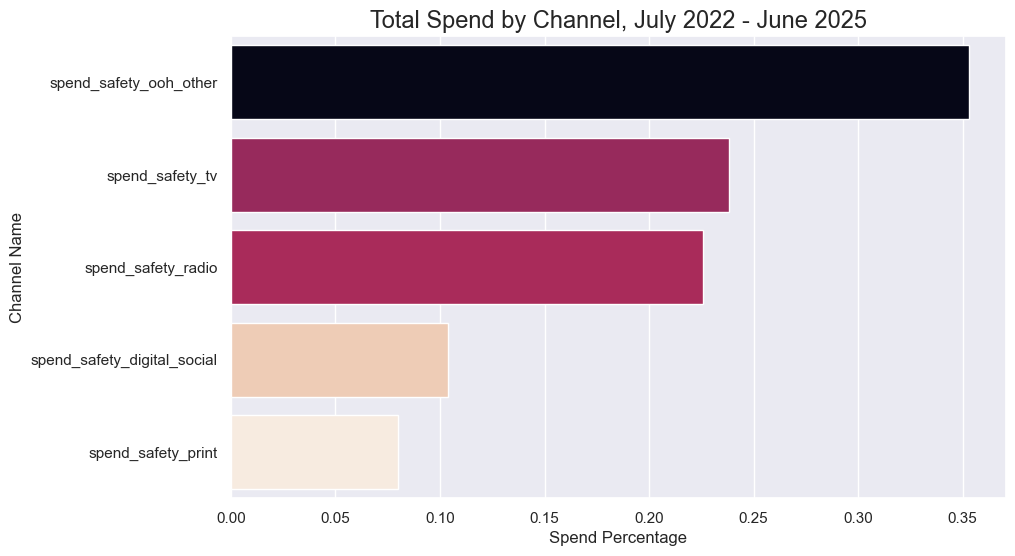

In [14]:
# Bar Chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=total_spend_by_channel_df,
    y=total_spend_by_channel_df["channel_name"],
    x="spent_pct",
    hue="spent_pct",
    palette="rocket_r",
    legend=False
)

plt.xlabel("Spend Percentage")
plt.ylabel("Channel Name")
plt.title("Total Spend by Channel, July 2022 - June 2025", fontsize=17)

plt.show()

#### Advertising Channel Correlations

Radio spending was strongly correlated with Digital/Social and OOH/Other spending (r ≈ 0.90), suggesting overlapping campaign activity that could make individual channel contributions difficult to isolate during modeling.

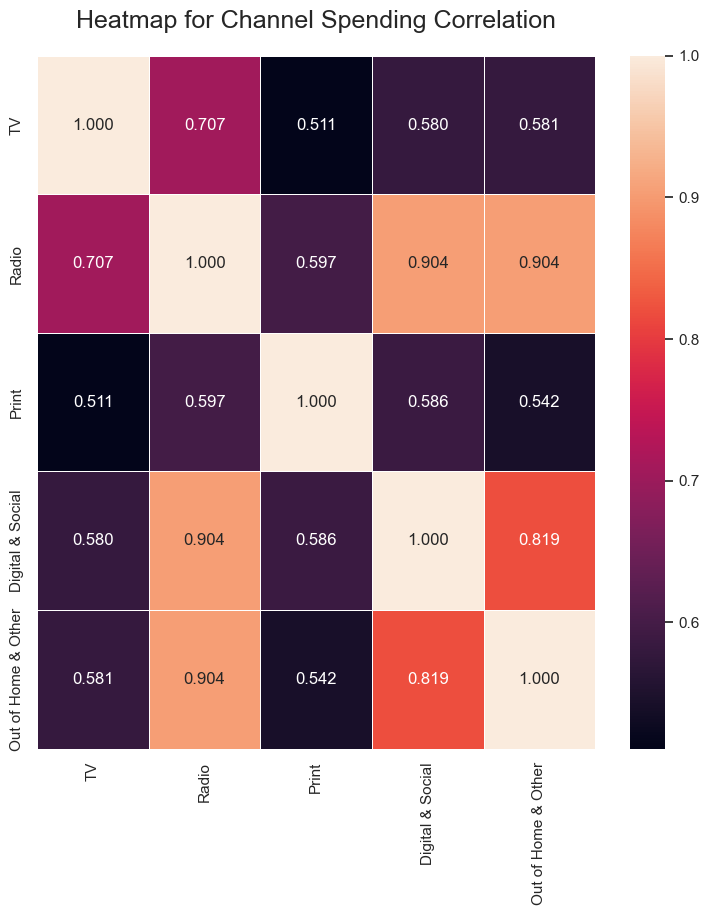

In [15]:
# Correlation matrix for spending channels
spend_cols_corr = data[spend_cols].corr()

# Plot size
plt.figure(figsize=(9,9))

# Axis labels
axis_labels=["TV", "Radio", "Print", "Digital & Social", "Out of Home & Other"]

# Heatmap
sns.heatmap(
    data=spend_cols_corr,
    annot=True,
    fmt=".3f",
    linewidth=.5,
    xticklabels=axis_labels,
    yticklabels=axis_labels
)

# Title
plt.title("Heatmap for Channel Spending Correlation", fontsize=18, pad=20)

# Show
plt.show()

#### Weekly Advertising Spending Trends

Advertising spending was highly intermittent across channels, with periods of substantial expenditures followed by extended gaps with little or no activity.

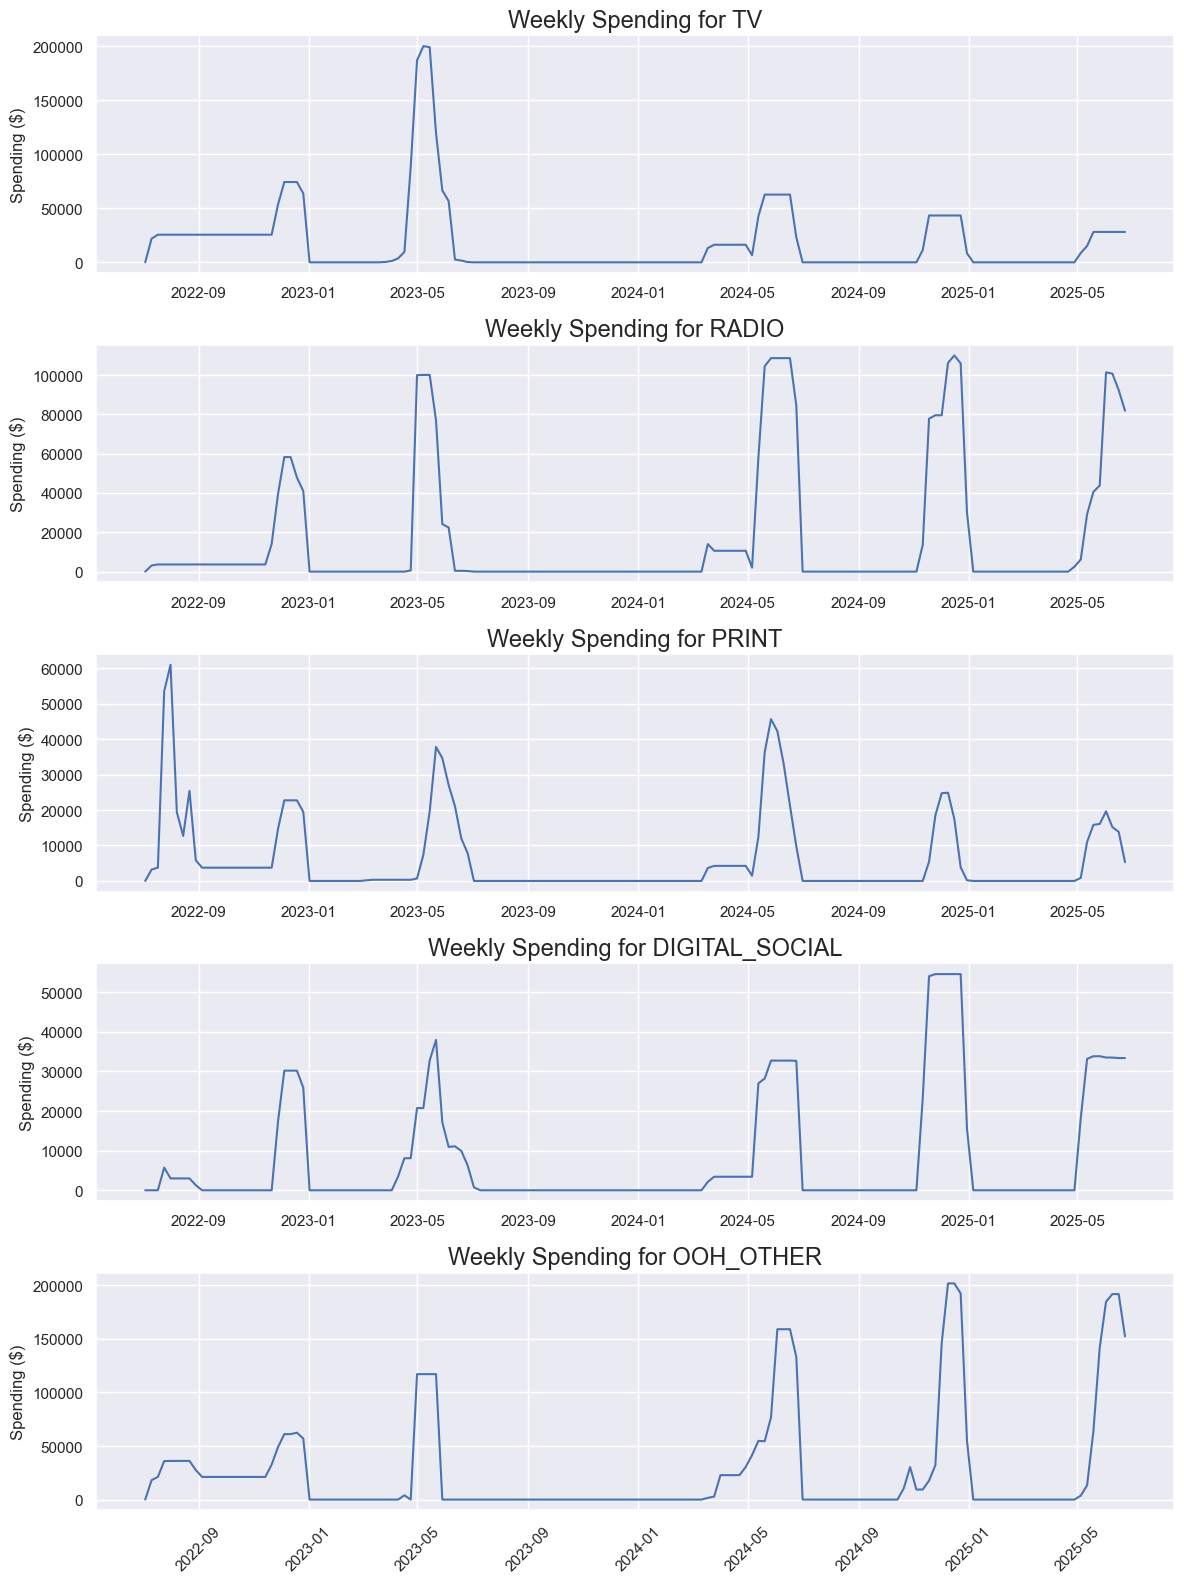

In [16]:
# Weekly spending dataframe
weekly_spending = data[["week_start", *spend_cols]]

fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 16),
    sharex=False
)

for ax, s in zip(axes, spend_cols):
    cleaned_label = s.split("spend_safety_")[1].upper()
    ax.plot(weekly_spending["week_start"], weekly_spending[s])
    ax.set_title(f"Weekly Spending for {cleaned_label}", fontsize=17)
    ax.set_ylabel("Spending ($)")
    
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Average Weekly Crashes and Injuries by Month

Average weekly crashes and injuries rose through spring and summer, peaked in September–October, and declined from November, suggesting seasonal patterns that should be accounted for in the model.

In [17]:
# Weekly Crashes and injured
monthly_crash_injured = pd.DataFrame(
    data.groupby(data["week_start"].dt.month)[["crashes", "injured"]].mean()
).round(2)

monthly_crash_injured.index.name = "month"

monthly_crash_injured

,crashes,injured
month,,
1,1634.14,863.64
2,1636.08,881.75
3,1729.85,959.31
4,1704.08,961.77
5,1877.38,1077.46
6,1837.08,1077.92
7,1851.71,1105.57
8,1859.31,1102.69
9,1925.23,1087.08


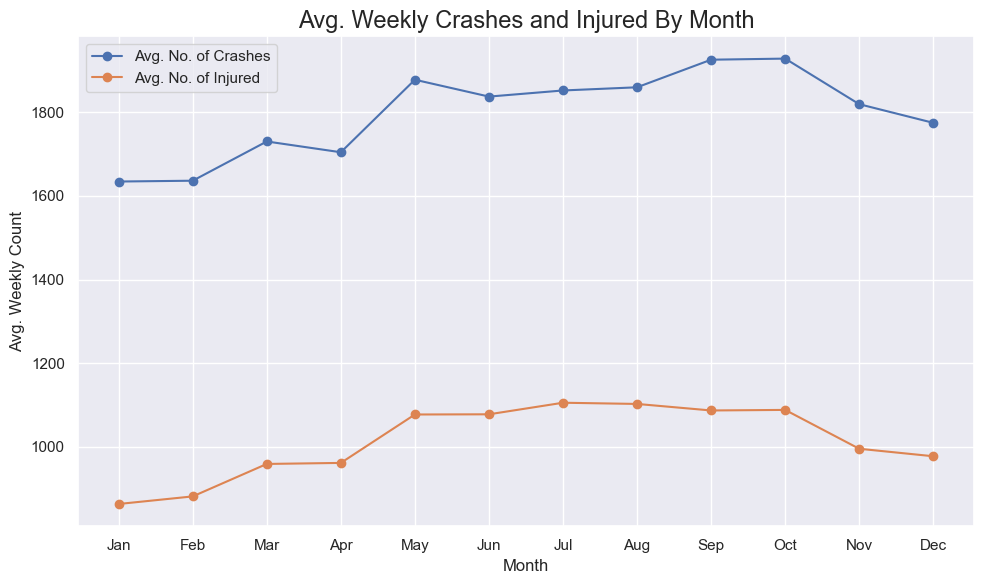

In [18]:
# Plot weekly crashes and injured
plt.figure(figsize=(10, 6))

plt.plot(monthly_crash_injured.index, monthly_crash_injured["crashes"], label="Avg. No. of Crashes", marker="o")
plt.plot(monthly_crash_injured.index, monthly_crash_injured["injured"], label="Avg. No. of Injured", marker="o")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Avg. Weekly Crashes and Injured By Month", fontsize=17)
plt.xlabel("Month")
plt.ylabel("Avg. Weekly Count")

plt.legend()
plt.tight_layout()
plt.show()

#### Advertising Spending Distributions

During weeks with advertising activity, TV, Radio, Print, and OOH/Other exhibited right-skewed spending distributions, while Digital/Social showed multiple peaks. Weekly advertising expenditures varied considerably across channels.

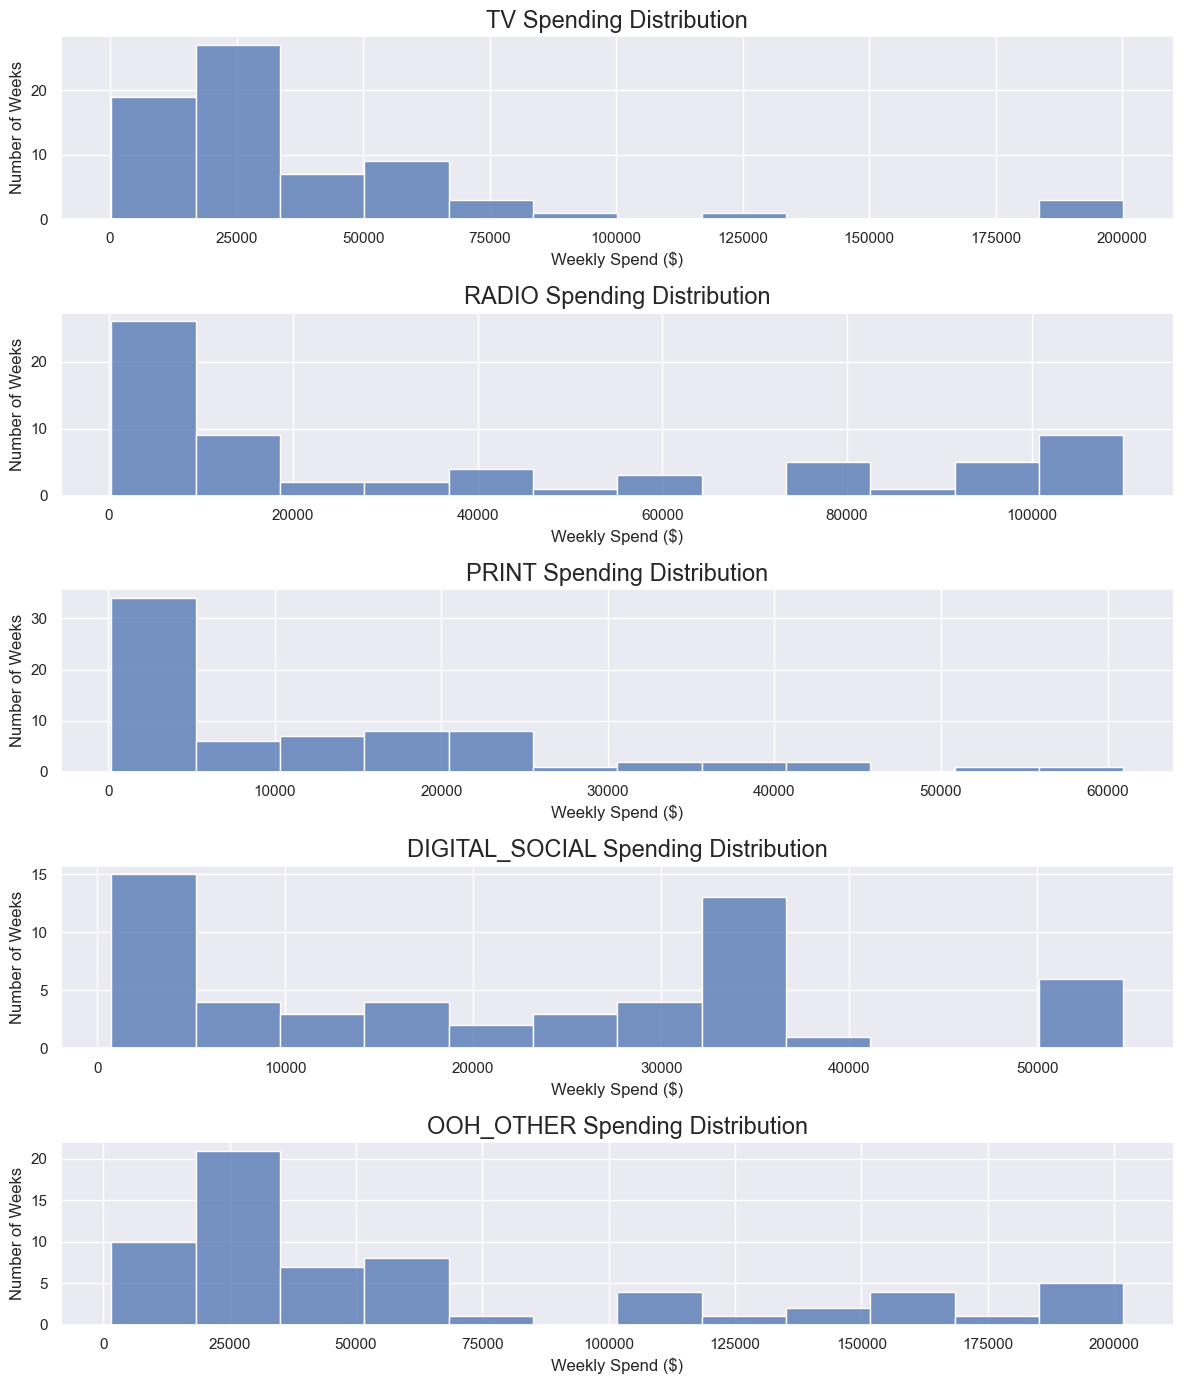

In [19]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 14)
)

axes = axes.flatten()

for ax, s in zip(axes, spend_cols):
    # Only weeks with actual spending
    active_spend = data.loc[data[s] > 0, s]

    # Clean channel name
    channel = s.replace("spend_safety_", "").upper()

    sns.histplot(
        active_spend,
        bins=12,
        ax=ax
    )

    ax.set_title(f"{channel} Spending Distribution", fontsize=17)
    ax.set_xlabel("Weekly Spend ($)")
    ax.set_ylabel("Number of Weeks")

plt.tight_layout()
plt.show()

#### Advertising Spending vs. Crash Outcomes

TV and Print spending showed the strongest positive correlations with weekly crashes and injuries. However, these relationships were relatively modest and do not establish causality, highlighting the importance of accounting for other factors during modeling.

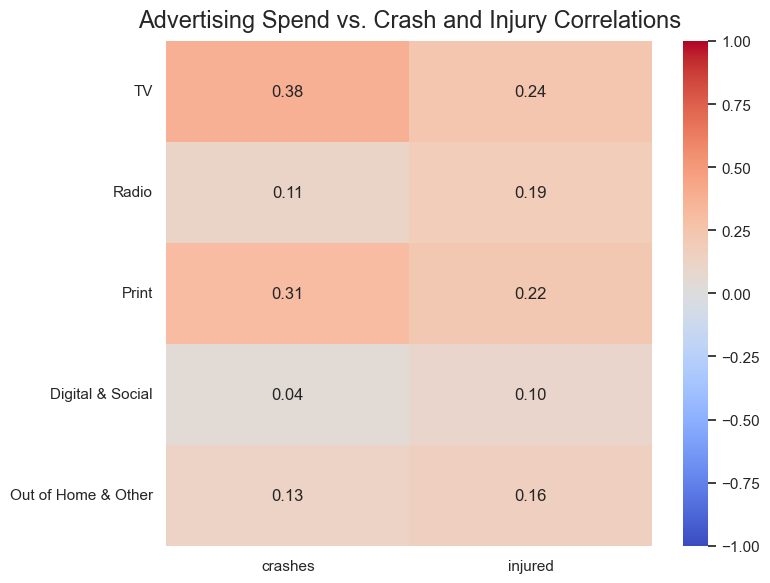

In [20]:
# Correlation between channel spending and outcomes
spend_outcome_corr = data[
    spend_cols + ["crashes", "injured"]
].corr()

# Keep only channel vs. outcome correlations
spend_outcome_corr = spend_outcome_corr.loc[
    spend_cols, ["crashes", "injured"]
]

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    spend_outcome_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    yticklabels=axis_labels
)

plt.title("Advertising Spend vs. Crash and Injury Correlations", fontsize=17, pad=10)
plt.tight_layout()
plt.show()